In [1]:
# Sel 1: Instalasi Library
!apt-get install tesseract-ocr
!pip install pytesseract opencv-python matplotlib

'apt-get' is not recognized as an internal or external command,
operable program or batch file.


   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
    --------------------------------------- 1.0/44.0 MB 4.6 MB/s eta 0:00:10
   -- ------------------------------------- 2.4/44.0 MB 5.2 MB/s eta 0:00:09
   --- ------------------------------------ 3.9/44.0 MB 5.6 MB/s eta 0:00:08
   ---- ----------------------------------- 5.2/44.0 MB 6.0 MB/s eta 0:00:07
   ------ --------------------------------- 7.1/44.0 MB 6.3 MB/s eta 0:00:06
   ------- -------------------------------- 8.7/44.0 MB 6.5 MB/s eta 0:00:06
   --------- ------------------------------ 10.7/44.0 MB 7.1 MB/s eta 0:00:05
   ----------- ---------------------------- 13.1/44.0 MB 7.6 MB/s eta 0:00:05
   -------------- ------------------------- 15.5/44.0 MB 7.9 MB/s eta 0:00:04
   --------------- ------------------------ 17.6/44.0 MB 8.2 MB/s eta 0:00:04
   ------------------ --------------------- 20.2/44.0 MB 8.5 MB/s eta 0:00:03
   -----


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import cv2
import pytesseract
import numpy as np
import matplotlib.pyplot as plt
import os

# Tentukan folder tempat gambar disimpan
folder_path = 'Data'

# Ambil semua file berformat .jpeg / .jpg / .png di dalam folder Data
exts = ('.jpeg', '.jpg', '.png')
daftar_gambar = [f for f in os.listdir(folder_path) if f.lower().endswith(exts)]

data_ijazah = {}

if daftar_gambar:
    for filename in sorted(daftar_gambar):
        # Menyimpan path lengkap file gambar, contoh: 'Data/1.jpeg'
        full_path = os.path.join(folder_path, filename)
        data_ijazah[full_path] = {}
        
    print(f"Berhasil memuat {len(data_ijazah)} file gambar:")
    for path in data_ijazah.keys():
        print(f"- {path}")
    print("\nLanjut ke Sel 3.")
else:
    print(f"Tidak ada file gambar yang ditemukan di dalam folder '{folder_path}'!")

Berhasil memuat 9 file gambar:
- Data\1.jpeg
- Data\2.jpeg
- Data\3.jpeg
- Data\4.jpeg
- Data\5.jpeg
- Data\6.jpeg
- Data\7.jpeg
- Data\8.jpeg
- Data\9.jpeg

Lanjut ke Sel 3.


In [13]:
# ==========================================
# SEL 3: PIPELINE PRE-PROCESSING
# ==========================================
for filename, data in data_ijazah.items():
    img = cv2.imread(filename)
    if img is None:
        print(f"Gagal memuat gambar: {filename}")
        continue

    # Rotasi 90 derajat searah jarum jam (Sesuai template ijazah vertikal)
    img_rotated = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

    # Grayscale & CLAHE Enhancement
    gray = cv2.cvtColor(img_rotated, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

    # Simpan hasil pre-processing ke dictionary
    data['enhanced_gray'] = clahe.apply(gray)

print("Pre-processing (Rotasi & Enhancement) selesai untuk semua file.")

Pre-processing (Rotasi & Enhancement) selesai untuk semua file.


In [ ]:
# ==========================================
# SEL 4: PEMOTONGAN AREA (ROI)
# ==========================================
for filename, data in data_ijazah.items():
    img = cv2.imread(filename)
    if img is None:
        print(f"Gagal memuat {filename}")
        continue

    # 1. Rotasi 90 derajat searah jarum jam agar gambar tegak (Portrait)
    img_rotated = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

    # Grayscale & CLAHE Enhancement
    gray = cv2.cvtColor(img_rotated, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced_gray = clahe.apply(gray)
    data['enhanced_gray'] = enhanced_gray

    H, W = enhanced_gray.shape

    # 2. Potong berdasarkan posisi asli ijazah UI:
    # Area Nomor Ijazah -> KANAN ATAS
    # Y: 2% - 10% (Paling atas) | X: 55% - 95% (Area kanan)
    data['roi_nomor'] = enhanced_gray[int(H * 0.02) : int(H * 0.10), int(W * 0.55) : int(W * 0.95)]

    # Area Tanda Tangan Rektor -> KANAN BAWAH (Hindari foto kiri & barcode bawah)
    # Y: 72% - 88% (Di atas barcode) | X: 60% - 98% (Di kanan foto)
    data['roi_ttd'] = enhanced_gray[int(H * 0.72) : int(H * 0.88), int(W * 0.60) : int(W * 0.98)]

print("Pemotongan Area (ROI) Selesai.")

Pemotongan Area (ROI) Selesai.


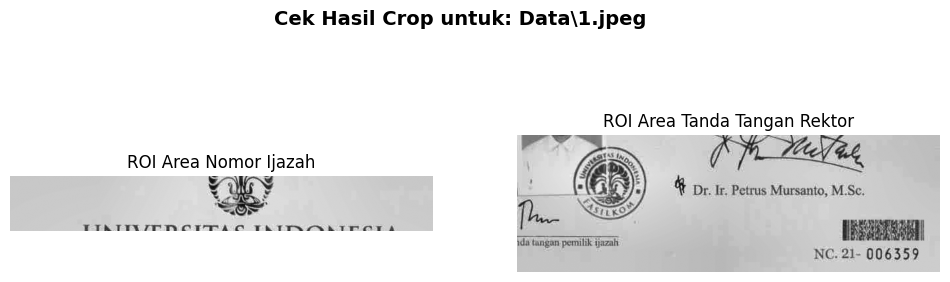

--------------------------------------------------


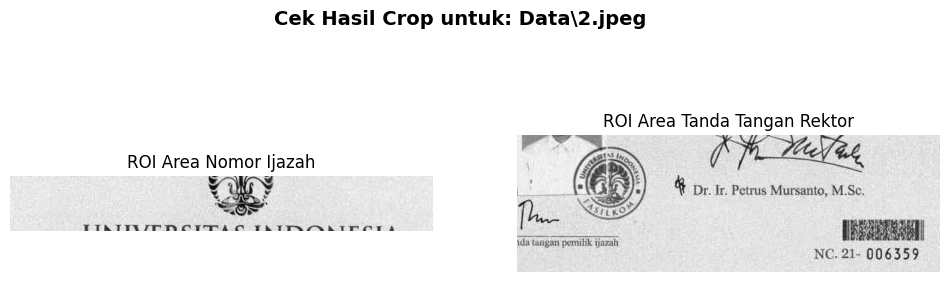

--------------------------------------------------


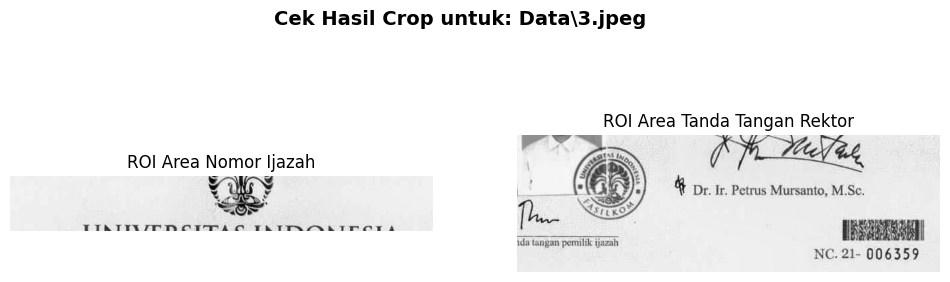

--------------------------------------------------


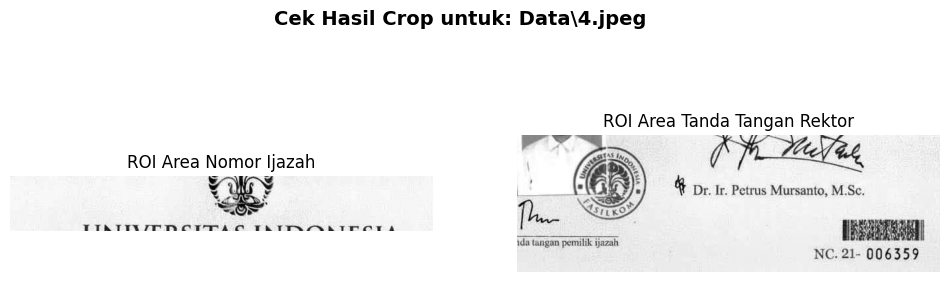

--------------------------------------------------


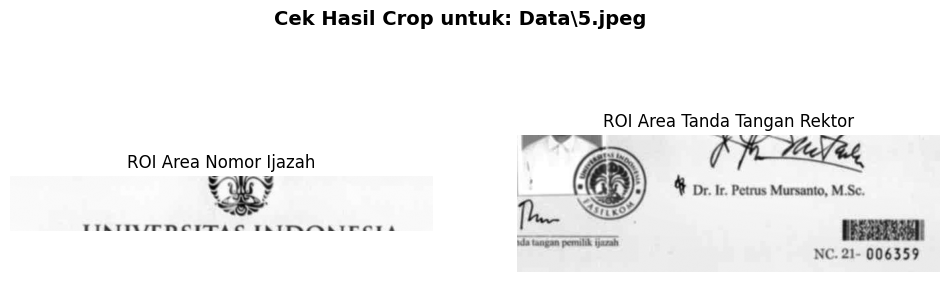

--------------------------------------------------


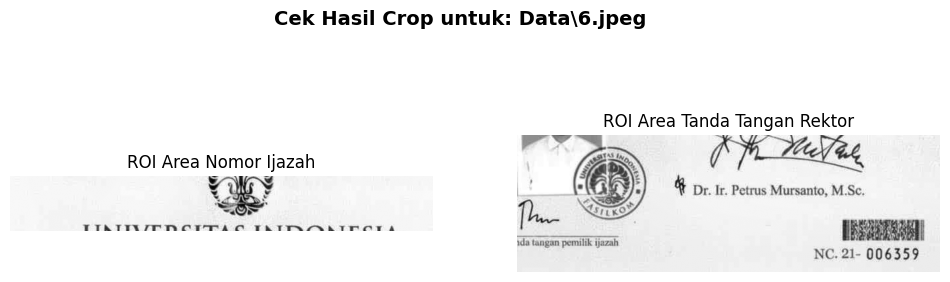

--------------------------------------------------


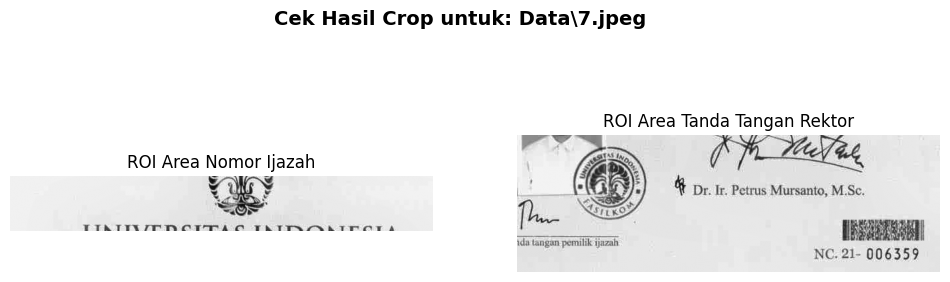

--------------------------------------------------


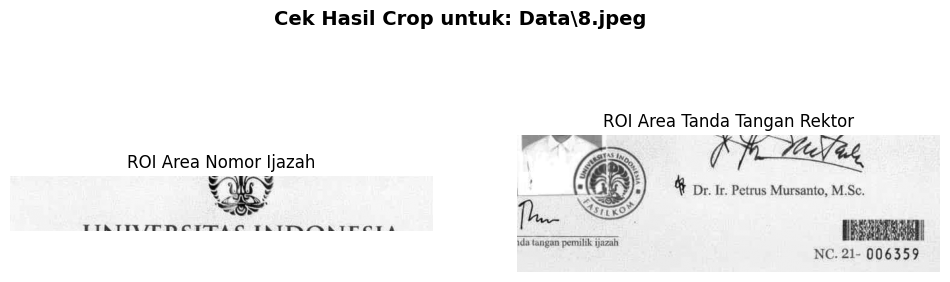

--------------------------------------------------


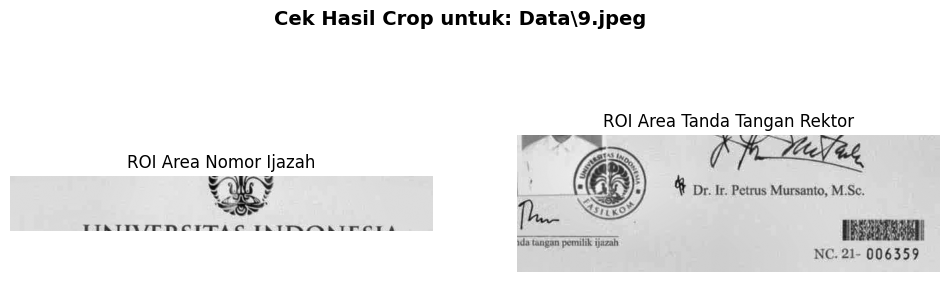

--------------------------------------------------


In [12]:
# ==========================================
# SEL 5: VISUALISASI HASIL CROP (ROI)
# ==========================================
import matplotlib.pyplot as plt

for filename, data in data_ijazah.items():
    if 'roi_nomor' not in data or 'roi_ttd' not in data:
        continue

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f"Cek Hasil Crop untuk: {filename}", fontsize=14, fontweight='bold')

    # Menampilkan potongan area nomor ijazah
    ax[0].imshow(data['roi_nomor'], cmap='gray')
    ax[0].set_title('ROI Area Nomor Ijazah')
    ax[0].axis('off')

    # Menampilkan potongan area tanda tangan
    ax[1].imshow(data['roi_ttd'], cmap='gray')
    ax[1].set_title('ROI Area Tanda Tangan Rektor')
    ax[1].axis('off')

    plt.show()
    print("-" * 50)